# ai33 opening voice: measured latency

Read saved results, inspect stages and draw charts. Running this notebook does **not** call ai33, read API keys, start a model or train anything.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/report_ai33_latency.py').is_file())
sys.path.insert(0, str(ROOT))
from scripts.report_ai33_latency import read_record, metadata, stage_rows, request_rows, plot_stages, LIMITS
SUMMARY = ROOT / 'data/generated/ai33-opening-latency-v1/summary.json'
OUT = ROOT / 'data/generated/ai33-opening-latency-v1'
OUT.mkdir(parents=True, exist_ok=True)
record = read_record(SUMMARY)
print('Loaded recorded results:', SUMMARY)

Loaded recorded results: D:\NCC\MDD\data\generated\ai33-opening-latency-v1\summary.json


## Voice and authored opening

Sarah's public voice ID, speed, input length and audio duration come from the saved probe. No learner recording was sent.

In [2]:
display(pd.DataFrame(metadata(record).items(), columns=['field', 'recorded value']))

,field,recorded value
0,measurement started (UTC),2026-10-23T02:18:09.429058+00:00
1,topic,daily-life
2,voice,"Sarah — Mature, Reassuring, Confident"
3,public voice ID,elevenlabs_EXAVITQu4vr4xnSDxMaL
4,speed,1.0
5,authored opening,Hi! Let's talk about your day. What do you usu...
6,word count (whitespace separated),15
7,audio duration seconds,4.821
8,provider polling interval seconds,2.0
9,new tasks submitted,1


## Initial call: stage table

Submission, provider waiting/status polling and audio download are separate timers. Waiting includes the configured polling interval; it is not pure synthesis time.

In [3]:
stages = pd.DataFrame(stage_rows(record))
display(stages.round(4))
print('Provider polling interval:', record['provider_poll_interval_sec'], 'seconds')
print('Status polls:', record['runs'][0]['timing']['poll_count'])

,stage,seconds
0,Local cache lookup,0.0001
1,Submit ai33 task,0.2830
2,Wait / status polling,6.6382
3,Download audio,0.8293
4,Other measured bookkeeping,0.0011
5,Total backend client,7.7516


Provider polling interval: 2.0 seconds
Status polls: 4


## Purple / white latency chart

Each bar is a recorded observation, not an average across many calls. The exact cached repeat is too small to appear at the initial-call scale; its label and table retain the measured time.

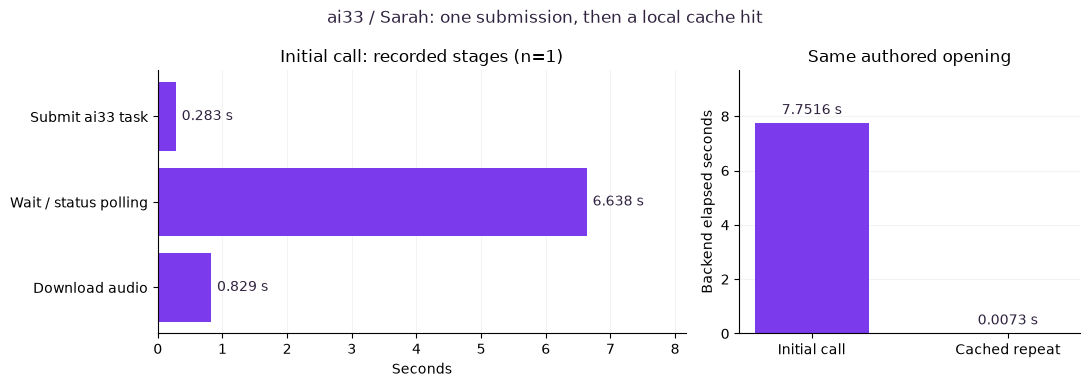

In [4]:
figure = plot_stages(record)
figure.savefig(OUT / 'stages.png', dpi=160, facecolor='white')
plt.show()

## Exact cached repeat

The same text, voice and speed reused the same audio bytes. This measures the backend's local cache path, not browser playback or a second voice-generation request.

In [5]:
display(pd.DataFrame(request_rows(record)).round(4))
print('Same audio SHA256:', record['runs'][0]['audio_sha256'] == record['runs'][1]['audio_sha256'])
print('Total new tasks:', record['new_task_posts_total'])

,request,elapsed seconds,cache hit,new tasks,provider requests,audio downloads,audio duration seconds
0,initial call,7.7516,False,1,5,1,4.821
1,cached repeat,0.0073,True,0,0,0,4.821


Same audio SHA256: True
Total new tasks: 1


## Interpretation limits

- One authored opening (n=1), followed by one exact cached repeat (n=1). This is not an estimate of typical or worst-case provider latency.
- Timings cover the backend provider client: task submission, task-status polling, audio download and local cache lookup. Browser HTTP, ngrok, decoding, playback start and word highlighting are not measured.
- The wait stage includes provider processing, status HTTP requests and the configured polling sleeps. It is not a direct measurement of pure synthesis time.
- Only one new ai33 task was submitted. The cached repeat reused the same audio bytes and made no provider status or submission requests, and no audio download.
- No learner recording was sent. The measured text is an authored topic opening; no LLM call or training was part of this probe.
- Adding a UI pause changes presentation timing, not the measured provider generation time. Report generation itself makes no API calls.

In [6]:
print(json.dumps({'source': str(SUMMARY), 'source_sha256': hashlib.sha256(SUMMARY.read_bytes()).hexdigest(), 'measurement_started_utc': record['started_at_utc'], 'scope': record['scope']}, indent=2))
print('This notebook submitted no tasks and made no provider requests.')

{
  "source": "D:\\NCC\\MDD\\data\\generated\\ai33-opening-latency-v1\\summary.json",
  "source_sha256": "adde45fb1550aa598720ded1887392704601baead5db27274f82ce62e10e17d7",
  "measurement_started_utc": "2026-10-23T02:18:09.429058+00:00",
  "scope": "One authored opening, then exact cached repeat."
}
This notebook submitted no tasks and made no provider requests.


## Optional: a separately authorized new measurement

The following command is documentation only; it is deliberately not an executable notebook cell. It uses the configured API and can incur a charge. The benchmark enforces **at most one new ai33 task**, followed by an exact cached repeat. An existing receipt/cache may mean no new task is needed. Use a new output folder to keep the current evidence.

```powershell
.\.venv\Scripts\python.exe -X utf8 scripts\benchmark_ai33_opening.py --run --topic auto --output data/generated/ai33-opening-latency-next
```

To regenerate this report without calling any API:

```powershell
.\.venv\Scripts\python.exe -X utf8 scripts\report_ai33_latency.py
```